# Notebook 05 — EWMA Volatility and Dynamic VaR

Financial market volatility changes over time. Periods of high volatility often cluster together, while calmer periods tend to remain relatively stable.

This notebook implements the Exponentially Weighted Moving Average (EWMA) model introduced by J.P. Morgan's RiskMetrics framework. The model assigns greater weight to recent observations, allowing volatility estimates to adjust more quickly to changing market conditions.

The estimated volatility is then used to calculate dynamic Value at Risk (VaR) and Expected Shortfall (ES).

**RiskMetrics Parameter**
 λ = 0.94

## Outputs

- Current EWMA volatility
- EWMA VaR (95%, 99%)
- Rolling volatility and VaR visualizations


EWMA VaR (95%)
Current Volatility : 0.8900%
VaR                : 1.4640% ($14,640)
ES                 : 1.8359% ($18,359)

EWMA VaR (99%)
Current Volatility : 0.8900%
VaR                : 2.0706% ($20,706)
ES                 : 2.3722% ($23,722)


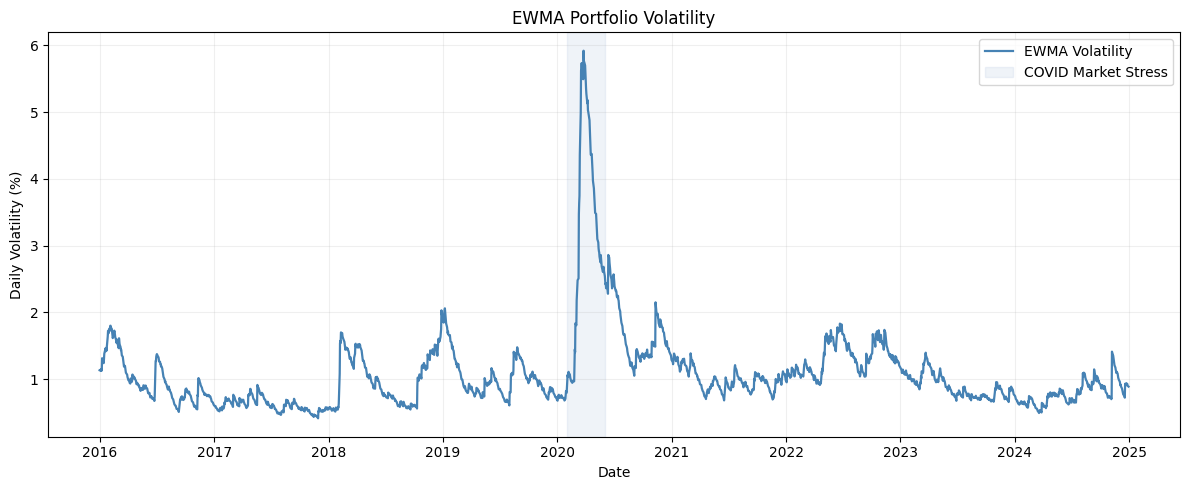

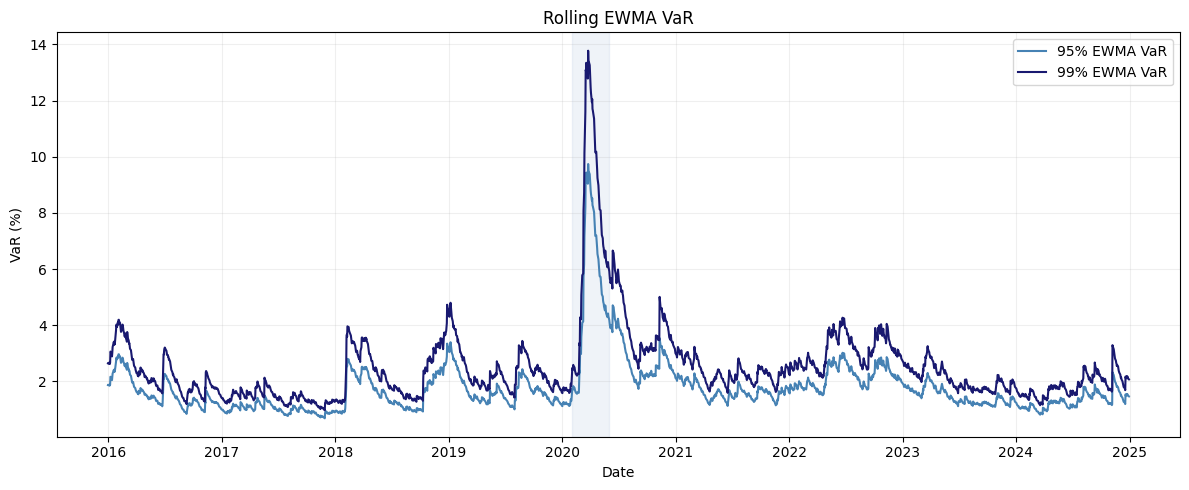

In [2]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option('display.float_format', '{:.4f}'.format)

# Configuration

weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])
confidence_levels = [0.95, 0.99]
portfolio_value = 1_000_000
lam = 0.94

# Load Data

log_returns = pd.read_csv("../data/log_returns.csv", index_col=0, parse_dates=True)
simple_returns = np.exp(log_returns) - 1
portfolio_simple_returns = simple_returns.dot(weights)
portfolio_returns = np.log1p(portfolio_simple_returns)

# EWMA Volatility

n = len(portfolio_returns)
r = portfolio_returns.values
burn_in = 250

ewma_var = np.full(n, np.nan)
ewma_var[burn_in] = np.var(r[:burn_in])

for t in range(burn_in + 1, n):
    ewma_var[t] = (lam * ewma_var[t - 1]
        + (1 - lam) * r[t - 1] ** 2)

ewma_vol = np.sqrt(ewma_var)

# EWMA VaR

ewma_results = {}

for cl in confidence_levels:

    z = norm.ppf(1 - cl)
    var_pct = -z * ewma_vol[-1]
    es_pct  = ewma_vol[-1] * norm.pdf(z) / (1 - cl)
    var_dollar = var_pct * portfolio_value
    es_dollar = es_pct * portfolio_value

    ewma_results[cl] = {
        "var_pct": var_pct,
        "es_pct": es_pct,
        "var_dollar": var_dollar,
        "es_dollar": es_dollar}

    print(f"\nEWMA VaR ({cl*100:.0f}%)")
    print(f"Current Volatility : {ewma_vol[-1]*100:.4f}%")
    print(f"VaR                : {var_pct*100:.4f}% (${var_dollar:,.0f})")
    print(f"ES                 : {es_pct*100:.4f}% (${es_dollar:,.0f})")

# Rolling EWMA VaR

ewma_var_95 = -norm.ppf(0.05) * ewma_vol
ewma_var_99 = -norm.ppf(0.01) * ewma_vol
dates = portfolio_returns.index

# Visualization 1

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    dates,
    ewma_vol * 100,
    color="steelblue",
    linewidth=1.6,
    label="EWMA Volatility")

ax.axvspan(
    "2020-02-01",
    "2020-06-01",
    color="lightsteelblue",
    alpha=0.20,
    label="COVID Market Stress")

ax.set_title("EWMA Portfolio Volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Volatility (%)")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

os.makedirs("../reports", exist_ok=True)
plt.savefig("../reports/05_ewma_volatility.png", dpi=150)
plt.show()

# Visualization 2

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    dates,
    ewma_var_95 * 100,
    color="steelblue",
    linewidth=1.5,
    label="95% EWMA VaR")

ax.plot(
    dates,
    ewma_var_99 * 100,
    color="midnightblue",
    linewidth=1.5,
    label="99% EWMA VaR")

ax.axvspan(
    "2020-02-01",
    "2020-06-01",
    color="lightsteelblue",
    alpha=0.20)

ax.set_title("Rolling EWMA VaR")
ax.set_xlabel("Date")
ax.set_ylabel("VaR (%)")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("../reports/05_ewma_var.png", dpi=150)
plt.show()